# **Tutorial:** Introduction to Large Language Models (LLMs) with HuggingFace

Notebook edited by: Darío Julián Echeverría Castro

## Objective:
The goal of this workshop is to introduce students to the basic concepts of large language models (LLMs) and give them hands-on experience using Hugging Face libraries to work with pretrained natural language models.

## Contents:
1. Introduction to Large Language Models (LLMs)
2. Environment setup
3. Practical examples
4. Exercise

## 1. Introduction to Large Language Models (LLMs)

Large language models (LLMs) are AI models trained on huge amounts of text to understand and generate natural language. These models can perform a variety of natural language processing (NLP) tasks such as translation, summarization, text generation, question answering, and more.

## 2. Environment setup

For this workshop, we'll use the Hugging Face `transformers` library. First, we need to install the required packages.

In [1]:
# Install the transformers and torch libraries
%pip install transformers
%pip install torch

  Using cached click-8.5.1-py3-none-any.whl.metadata (2.6 kB)
  Using cached filelock-4.2.10-py3-none-any.whl.metadata (2.3 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached shellingham-1.5.4-py2.py3-none-any.whl.metadata (3.5 kB)
  Using cached annotated_doc-0.0.6-py3-none-any.whl.metadata (6.5 kB)
   ---------------------------------------- 0.0/13.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/13.3 MB ? eta -:--:--
   - -------------------------------------- 0.5/13.3 MB 2.2 MB/s eta 0:00:06
   ----- ---------------------------------- 1.8/13.3 MB 5.3 MB/s eta 0:00:03
   --------------- ------------------------ 5.2/13.3 MB 9.0 MB/s eta 0:00:01
   ---------------------------- ----------- 9.4/13.3 MB 13.1 MB/s eta 0:00:01
   ---------------------------------------- 13.3/13.3 MB 13.6 MB/s  0:00:01
   ---------------------------------------- 0.0/857.0 kB ? eta -:--:--
   ---------------------------------------- 857.0/857.0 kB 25.8 MB/s 

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


  Using cached torch-2.15.0-cp313-cp313-win_amd64.whl.metadata (36 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
Using cached torch-2.15.0-cp313-cp313-win_amd64.whl (126.7 MB)
Using cached sympy-1.14.0-py3-none-any.whl (6.3 MB)
Using cached mpmath-1.3.0-py3-none-any.whl (536 kB)

   ---------------------------------------- 0/3 [mpmath]
   ---------------------------------------- 0/3 [mpmath]
   ---------------------------------------- 0/3 [mpmath]
   ------------- -------------------------- 1/3 [sympy]
   ------------- -------------------------- 1/3 [sympy]
   ------------- -------------------------- 1/3 [sympy]
   ------------- -------------------------- 1/3 [sympy]
   ------------- -------------------------- 1/3 [sympy]
   ------------- -------------------------- 1/3 [sympy]
   ------------- -------------------------- 1/3 [sympy]
   ------------- -------------------------- 1/3 [sympy]
   ------------- 

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


We import `pipeline` from the `transformers` library

In [2]:
from transformers import pipeline

In [3]:
# Avoids kernel crashes from duplicate OpenMP runtimes (common on macOS)
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
# This environment also has TensorFlow installed; force transformers to use only PyTorch
os.environ["USE_TF"] = "0"
os.environ["USE_FLAX"] = "0"

## 3. Practical examples of loading and using pretrained models

### 3.1 Text generation (`text-generation`)

Let's load a pretrained Hugging Face model and use it to generate text.
The model weights around 1GB, so it may take a few minutes to download and load the model into memory.

In [4]:
# Load a text-generation pipeline with a small, current instruct model
generator = pipeline('text-generation', model='Qwen/Qwen2.5-0.5B-Instruct')

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

c:\Users\darth\.conda\envs\env_mcd\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\darth\.cache\huggingface\hub\models--Qwen--Qwen2.5-0.5B-Instruct. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\darth\.conda\envs\env_mcd\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `hu

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

In [6]:
# Instruct-tuned models expect a "messages" format (like a chat)
messages = [
    {"role": "user", # The role of the user is to provide input or instructions to the model. Other roles include "assistant" (the model's responses, meaning the model's output e,g.: "I think the answer is...") and "system" (instructions for the model).
     "content": "Once upon a time there was a kid who had a bike. Continue the story in 2 lines."
     }
]

text = generator(
    messages,
    max_new_tokens=80, # Maximum length of the generated text.
    num_return_sequences=1,
    temperature=0.7, # This parameter controls the randomness of the responses. Lower values make the model more predictable, while higher values make it more creative.
    )

# The model's reply is the last generated message
print(text[0]['generated_text'][-1]['content'])

The kid pedaled his bike down the street, joyfully riding through the city. He rode past colorful shops and bustling streets, feeling exhilarated at every step of the way. As he neared home, he felt a sense of accomplishment that only children can feel on such an incredible adventure.


Now let's use the model to generate text from several prompts

In [ ]:
# Example of text generation with different prompts
prompts = [
    "In the future, AI will",
    "The secret to happiness is",
    "The quick brown fox"
]

for prompt in prompts:
    messages = [{"role": "user", "content": prompt}]
    text = generator(messages, max_new_tokens=60, num_return_sequences=1)
    print(f"Prompt: {prompt}")
    print(f"Generated Text: {text[0]['generated_text'][-1]['content']}\n")

> **Note:** *gated* models (Llama, Mistral) require `huggingface-cli login`. The ones we use here are public.

### 3.2 Question answering (`question-answering`)

We can use a question-answering pipeline to find answers within a given context.

In [ ]:
# Load a question-answering pipeline
qa_pipeline = pipeline('question-answering')

# Define the context and the question
#context = "You are a mathematics teacher that can explain complex concepts in simple terms."
context = (
    "Artificial intelligence (AI) is a branch of computer science that aims to create machines that can perform tasks that would normally require human intelligence. "
    "Machine learning (ML) is a subset of AI that involves the use of algorithms and statistical models to enable computers to improve their performance on a task through experience. "
    "One common application of ML is in the field of natural language processing (NLP), where algorithms are used to understand and generate human language. "
    "For example, GPT-4o is a state-of-the-art language model developed by OpenAI that can generate human-like text based on a given prompt."
)
question = "What is machine learning?"

# Get the answer
result = qa_pipeline(question=question, context=context)
print(f"Question: {question}")
print(f"Answer: {result['answer']}")

### 3.3 Text summarization (`summarization`)

Use a pretrained model to generate a summary of a long text.

In [ ]:
# Load a summarization pipeline
summarizer = pipeline('summarization')

# Long text to summarize
long_text = (
"Artificial intelligence (AI) refers to the simulation of human intelligence in machines that are programmed to think like humans and mimic their actions. The term can also apply to any machine that exhibits traits associated with a human mind, such as learning and problem-solving. The ideal characteristic of artificial intelligence is its ability to rationalize and take actions that have the best chance of achieving a specific goal. A subset of artificial intelligence is machine learning, which refers to the idea that computer systems can learn from data, identify patterns, and make decisions with minimal human intervention."
)

# Generate the summary
summary = summarizer(long_text, max_length=50, min_length=25)
print("Summary:")
print(summary[0]['summary_text'])

### 3.4 Text translation (`translation`)

We use a pretrained English-to-Spanish translation model

In [ ]:
%pip install sentencepiece
import sentencepiece

# Load a translation pipeline, specifying the model
translation_pipeline = pipeline('translation', model='Helsinki-NLP/opus-mt-en-es')

# Define the text to translate
text = "Persistent homology is a method for computing topological features of a space at different spatial resolutions. More persistent features are detected over a wide range of spatial scales and are deemed more likely to represent true features of the underlying space rather than artifacts of sampling, noise, or particular choice of parameters"

# Get the translation
result = translation_pipeline(text)
print(f"Original text: {text}")
print(f"Translation: {result[0]['translation_text']}")

### 3.4 Sentiment analysis (`sentiment-analysis`)

Now we'll use a sentiment analysis model to predict whether a text is positive or negative.

In [ ]:
# Load the sentiment analysis pipeline
sentiment_analyzer = pipeline("sentiment-analysis")

# Text to analyze sentiment
text = "The price of the NVIDIA stock will increase tomorrow."
#text = "Today I have a quiz for the course Artificial Intelligence."
#text = "A cat is running in green fields in the summer."

# Perform sentiment analysis
sentiment_result = sentiment_analyzer(text)

# Print the sentiment result
print("Sentiment Analysis Result:")
for result in sentiment_result:
    print(f"Label: {result['label']}, Score: {result['score']}")

### 3.5 Asking questions to a table (`table-question-answering`)

Now let's ask questions to a Pandas DataFrame

In [ ]:
import pandas as pd

# Load a table-question-answering pipeline
#table_qa = pipeline("table-question-answering", model="google/tapas-base-finetuned-wtq")
table_qa = pipeline("table-question-answering")

#Create a table as a pandas DataFrame
table = {
    "Name": ["Karen", "Anna", "Pedro"],
    "Age": ["22", "31", "19"],  # Ensure all entries are strings
    "Interest": ["Cybersecurity", "Numerical Analysis", "Functional Analysis"]
}

# Question about the table
#question= "What is the interest of Karen?"
#question = "What is the age of Pedro?"
question = "What is the average age of the table?" # 22 + 31 + 19 = 72 / 3 = 24

# Generate the answer
answer = table_qa(table=table, query=question)

# Print the question and the answer
print("Question:", question)
print("Answer:", answer['answer'])

## Other tasks:

- 'audio-classification'
- 'automatic-speech-recognition'
- 'conversational'
- 'depth-estimation'
- 'document-question-answering'
- 'feature-extraction'
- 'fill-mask'
- 'image-classification'
- 'image-feature-extraction'
- 'image-segmentation'
- 'image-to-image'
- 'image-to-text'
- 'mask-generation'
- 'ner', 'object-detection'
- 'question-answering'
- 'sentiment-analysis'
- 'summarization'
- 'table-question-answering'
- 'text-classification'
- 'text-generation'
- 'text-to-audio'
- 'text-to-speech'
- 'text2text-generation'
- 'token-classification'
- 'translation'
- 'video-classification'
- 'visual-question-answering'
- 'vqa'
- 'zero-shot-audio-classification'
- 'zero-shot-classification'
- 'zero-shot-image-classification'
- 'zero-shot-object-detection'
- 'translation_XX_to_YY'

### **Individual Activity (30 min):** Comparing Recent Hugging Face Models

Pick a task (`text-generation`, `zero-shot-classification`, `summarization`, `sentiment-analysis`, etc.) and two recent, lightweight models different from the ones used here. Suggestions: `Qwen/Qwen2.5-1.5B-Instruct`, `HuggingFaceTB/SmolLM2-360M-Instruct`, `microsoft/Phi-3-mini-4k-instruct`, or explore [Trending on Hugging Face](https://huggingface.co/models).

Try both with the same input and compare: Size and performance of each model. Which one answered better or faster? Save the notebook as a PDF and upload it to Moodle.

*Estimated time:* 30 min

[transformers] `CLIPImageProcessor` requires torchvision (not installed); falling back to `CLIPImageProcessorPil` for backward compatibility. Install torchvision to use the default backend, or import `CLIPImageProcessorPil` directly to silence this warning.
[transformers] `SiglipImageProcessor` requires torchvision (not installed); falling back to `SiglipImageProcessorPil` for backward compatibility. Install torchvision to use the default backend, or import `SiglipImageProcessorPil` directly to silence this warning.
[transformers] `Siglip2ImageProcessor` requires torchvision (not installed); falling back to `Siglip2ImageProcessorPil` for backward compatibility. Install torchvision to use the default backend, or import `Siglip2ImageProcessorPil` directly to silence this warning.
c:\Users\darth\.conda\envs\env_mcd\Lib\site-packages\huggingface_hub\utils\_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a 

GPU disponible: True


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

c:\Users\darth\.conda\envs\env_mcd\Lib\site-packages\diffusers\pipelines\stable_diffusion_xl\pipeline_stable_diffusion_xl.py:750: FutureWarning: `upcast_vae` is deprecated and will be removed in version 1.0.0. `upcast_vae` is deprecated. Please use `pipe.vae.to(torch.float32)`. For more details, please refer to: https://github.com/huggingface/diffusers/pull/12619#issue-3606633695.
  deprecate(
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


SDXL-Turbo tardó 10.9 s


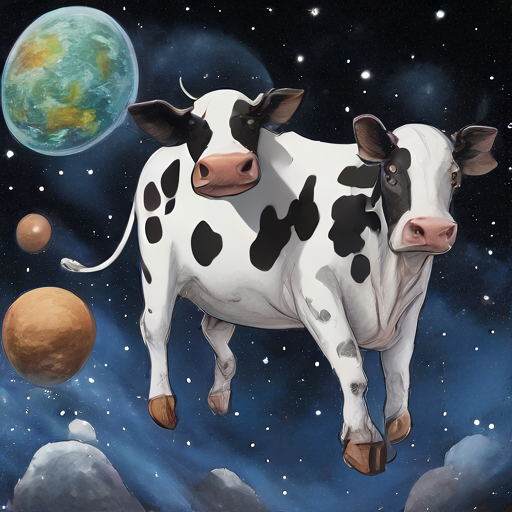

In [2]:
# SDXL-Turbo
import time, torch
from diffusers import AutoPipelineForText2Image

print("GPU disponible:", torch.cuda.is_available())  # Debe decir True

# Mismo prompt para ambos modelos
prompt = "Draw a cow floating in space, with planet Earth visible in the background. The cow should be wearing a space helmet."

# SDXL-Turbo: modelo destilado que genera una imagen en 1 solo paso
pipe_sdxl = AutoPipelineForText2Image.from_pretrained(
    "stabilityai/sdxl-turbo",
    torch_dtype=torch.float16,   # media precisión para ahorrar VRAM
    variant="fp16",
).to("cuda")

inicio = time.time()
imagen_sdxl = pipe_sdxl(
    prompt=prompt,
    num_inference_steps=1,       # Turbo está entrenado para 1-4 pasos
    guidance_scale=0.0,          # Turbo no usa guidance
    generator=torch.Generator("cuda").manual_seed(42),  # semilla para reproducibilidad
).images[0]
print(f"SDXL-Turbo tardó {time.time() - inicio:.1f} s")

imagen_sdxl.save("vaca_sdxl_turbo.png")
display(imagen_sdxl)

# Liberar la GPU antes de cargar Qwen
del pipe_sdxl
torch.cuda.empty_cache()


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

The config attributes {'force_upcast': True} were passed to AutoencoderKLFlux2, but are not expected and will be ignored. Please verify your config.json configuration file.


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

FLUX.2 klein tardó 11.5 s


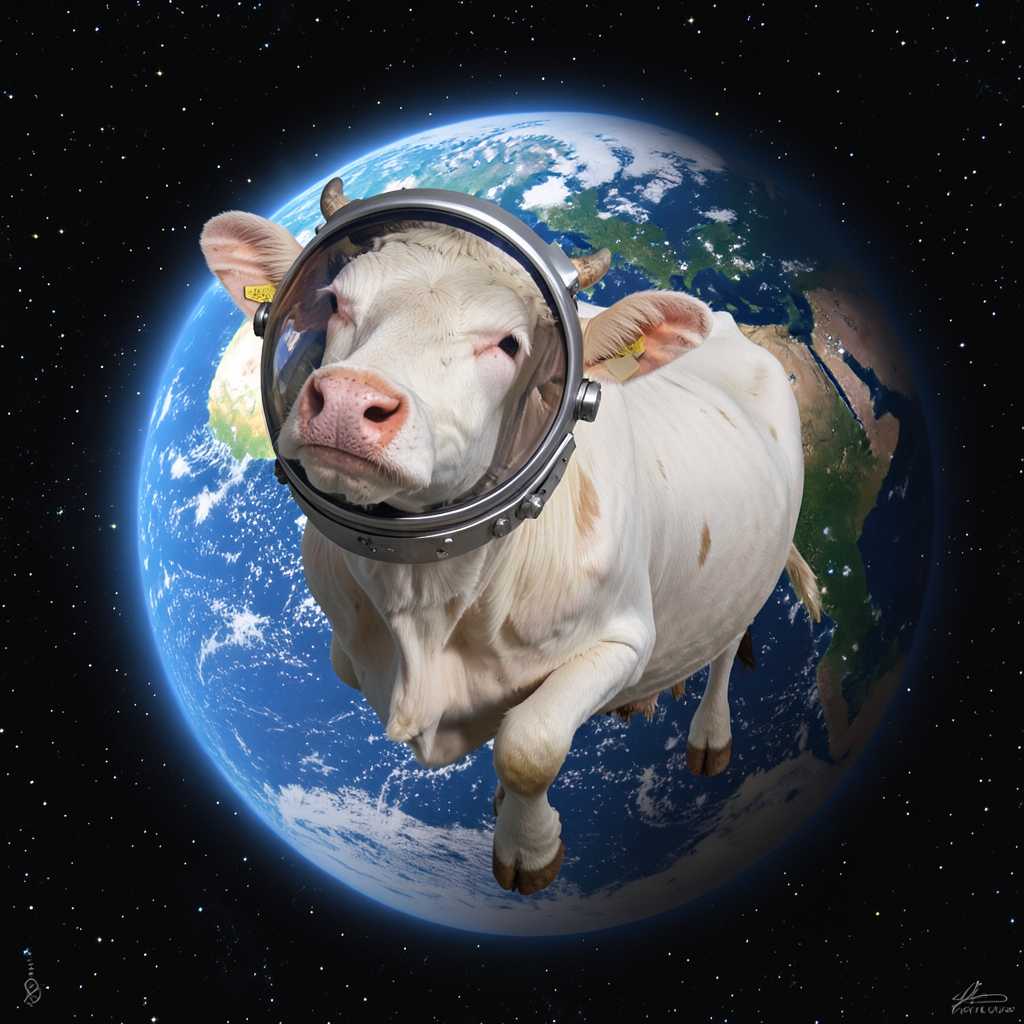

In [3]:
# FLUX.2 [klein] 4B
import time, torch
from diffusers import Flux2KleinPipeline
from diffusers.quantizers import PipelineQuantizationConfig

# ~13 GB en BF16 no caben en 8 GB de VRAM: cuantizamos a 4 bits (NF4)
quant_config = PipelineQuantizationConfig(
    quant_backend="bitsandbytes_4bit",
    quant_kwargs={
        "load_in_4bit": True,
        "bnb_4bit_quant_type": "nf4",
        "bnb_4bit_compute_dtype": torch.bfloat16,
    },
    components_to_quantize=["transformer", "text_encoder"],
)

pipe_flux = Flux2KleinPipeline.from_pretrained(
    "black-forest-labs/FLUX.2-klein-4B",
    torch_dtype=torch.bfloat16,
    quantization_config=quant_config,
)
pipe_flux.enable_model_cpu_offload()  # sube a la GPU solo el componente en uso

inicio = time.time()
imagen_flux = pipe_flux(
    prompt=prompt,               # mismo prompt de la Celda 1
    width=1024, height=1024,
    num_inference_steps=4,       # modelo destilado: 4 pasos bastan
    guidance_scale=1.0,
    generator=torch.Generator("cuda").manual_seed(42),
).images[0]
print(f"FLUX.2 klein tardó {time.time() - inicio:.1f} s")

imagen_flux.save("vaca_flux2_klein.png")
display(imagen_flux)


**Save this Notebook as a PDF and upload it to the designated activity on Moodle.**  

<p style="text-align: right; font-size:14px; color:gray;">
<b>Prepared by:</b><br>
Manuel Eugenio Morocho-Cayamcela
</p>